In [17]:
import sys

print(sys.executable)

c:\Users\PRIYANKA\Desktop\Cyber_Security_Projects\Network_Traffic_Anomaly_Detection\venv\Scripts\python.exe


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [19]:
df = pd.read_csv("network_traffic_dummy_2000.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 2000
Number of columns: 9


In [20]:
print(df.columns.tolist())

['Timestamp', 'SourceIp', 'DestinationIp', 'DestinationPort', 'Protocol', 'Service', 'PacketSize', 'BytesIn', 'BytesOut']


In [21]:
df.head()

,Timestamp,SourceIp,DestinationIp,DestinationPort,Protocol,Service,PacketSize,BytesIn,BytesOut
0,2026-01-01 00:00:38,192.168.1.38,10.0.0.17,443,TCP,HTTPS,761,4697,1700
1,2026-01-01 00:01:05,192.168.1.42,10.0.0.31,80,TCP,HTTP,584,4304,1112
2,2026-01-01 00:01:57,192.168.1.25,10.0.0.56,21,TCP,FTP,1263,3559,2333
3,2026-01-01 00:02:35,192.168.1.18,172.16.0.13,22,TCP,FTP,1170,6944,11635
4,2026-01-01 00:03:01,192.168.1.29,10.0.0.16,22,TCP,SSH,649,3551,1249


In [22]:
df.isnull().sum()

Timestamp          0
SourceIp           0
DestinationIp      0
DestinationPort    0
Protocol           0
Service            0
PacketSize         0
BytesIn            0
BytesOut           0
dtype: int64

In [23]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [24]:
df["TotalBytes"] = df["BytesIn"] + df["BytesOut"]

In [25]:
df["InOutRatio"] = df["BytesIn"] / (df["BytesOut"] + 1)

In [26]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

In [27]:
df["Hour"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

In [28]:
df["BytesPerPacket"] = df["TotalBytes"] / (df["PacketSize"] + 1)

In [29]:
# Convert Timestamp to datetime
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

# Feature 1: Total amount of data transferred
df["TotalBytes"] = df["BytesIn"] + df["BytesOut"]

# Feature 2: Ratio of incoming to outgoing traffic
df["InOutRatio"] = df["BytesIn"] / (df["BytesOut"] + 1)

# Feature 3: Hour of the day
df["Hour"] = df["Timestamp"].dt.hour

# Feature 4: Day of the week
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

# Feature 5: Total bytes relative to packet size
df["BytesPerPacket"] = df["TotalBytes"] / (df["PacketSize"] + 1)

print("Feature engineering completed successfully!")

df.head()

Feature engineering completed successfully!


,Timestamp,SourceIp,DestinationIp,DestinationPort,Protocol,Service,PacketSize,BytesIn,BytesOut,TotalBytes,InOutRatio,Hour,DayOfWeek,BytesPerPacket
0,2026-01-01 00:00:38,192.168.1.38,10.0.0.17,443,TCP,HTTPS,761,4697,1700,6397,2.761317,0,3,8.395013
1,2026-01-01 00:01:05,192.168.1.42,10.0.0.31,80,TCP,HTTP,584,4304,1112,5416,3.867026,0,3,9.258120
2,2026-01-01 00:01:57,192.168.1.25,10.0.0.56,21,TCP,FTP,1263,3559,2333,5892,1.524850,0,3,4.661392
3,2026-01-01 00:02:35,192.168.1.18,172.16.0.13,22,TCP,FTP,1170,6944,11635,18579,0.596769,0,3,15.865927
4,2026-01-01 00:03:01,192.168.1.29,10.0.0.16,22,TCP,SSH,649,3551,1249,4800,2.840800,0,3,7.384615


In [30]:
# Features that will be used by the Isolation Forest model

numeric_features = [
    "DestinationPort",
    "PacketSize",
    "BytesIn",
    "BytesOut",
    "TotalBytes",
    "InOutRatio",
    "Hour",
    "DayOfWeek",
    "BytesPerPacket"
]

categorical_features = [
    "Protocol",
    "Service"
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['DestinationPort', 'PacketSize', 'BytesIn', 'BytesOut', 'TotalBytes', 'InOutRatio', 'Hour', 'DayOfWeek', 'BytesPerPacket']

Categorical features:
['Protocol', 'Service']


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [32]:
X = df[numeric_features + categorical_features]

print("Shape of ML dataset:", X.shape)
print("\nFirst 5 rows:")
X.head()

Shape of ML dataset: (2000, 11)

First 5 rows:


,DestinationPort,PacketSize,BytesIn,BytesOut,TotalBytes,InOutRatio,Hour,DayOfWeek,BytesPerPacket,Protocol,Service
0,443,761,4697,1700,6397,2.761317,0,3,8.395013,TCP,HTTPS
1,80,584,4304,1112,5416,3.867026,0,3,9.258120,TCP,HTTP
2,21,1263,3559,2333,5892,1.524850,0,3,4.661392,TCP,FTP
3,22,1170,6944,11635,18579,0.596769,0,3,15.865927,TCP,FTP
4,22,649,3551,1249,4800,2.840800,0,3,7.384615,TCP,SSH


In [33]:
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline

# Create the Isolation Forest model
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.07,
    random_state=42,
    n_jobs=-1
)

# Combine preprocessing and Isolation Forest
model = Pipeline([
    ("preprocessor", preprocessor),
    ("isolation_forest", isolation_forest)
])

# Train the model
model.fit(X)

print("Isolation Forest model trained successfully!")

Isolation Forest model trained successfully!


In [34]:
# Predict whether each traffic record is normal or anomalous
df["Prediction"] = model.predict(X)

print(df["Prediction"].value_counts())

Prediction
 1    1860
-1     140
Name: count, dtype: int64


In [35]:
# Isolation Forest decision_function:
# higher values = more normal
# We reverse the sign so higher AnomalyScore = more suspicious

df["AnomalyScore"] = -model.decision_function(X)

print(df[[
    "SourceIp",
    "DestinationIp",
    "DestinationPort",
    "PacketSize",
    "BytesIn",
    "BytesOut",
    "AnomalyScore",
    "Prediction"
]].head(10))

       SourceIp DestinationIp  DestinationPort  PacketSize  BytesIn  BytesOut  \
0  192.168.1.38     10.0.0.17              443         761     4697      1700   
1  192.168.1.42     10.0.0.31               80         584     4304      1112   
2  192.168.1.25     10.0.0.56               21        1263     3559      2333   
3  192.168.1.18   172.16.0.13               22        1170     6944     11635   
4  192.168.1.29     10.0.0.16               22         649     3551      1249   
5  192.168.1.51     10.0.0.38               67         940     1118      1380   
6  192.168.1.23     10.0.0.24               21         674     2603      1135   
7  192.168.1.35     10.0.0.54               53         541     2198      2908   
8  192.168.1.20     10.0.0.17               53         853     3223      2975   
9  192.168.1.17     10.0.0.42               53         753     4296      4065   

   AnomalyScore  Prediction  
0     -0.105282           1  
1     -0.101784           1  
2     -0.115477   

In [36]:
# Create the final suspicious traffic output

suspicious_traffic = df[
    df["Prediction"] == -1
].copy()

suspicious_traffic = suspicious_traffic.sort_values(
    by="AnomalyScore",
    ascending=False
)

final_output = suspicious_traffic[[
    "SourceIp",
    "DestinationIp",
    "DestinationPort",
    "PacketSize",
    "BytesOut",
    "BytesIn",
    "AnomalyScore"
]].copy()

final_output = final_output.rename(columns={
    "BytesOut": "BytesSent",
    "BytesIn": "BytesReceived"
})

final_output.head(20)

,SourceIp,DestinationIp,DestinationPort,PacketSize,BytesSent,BytesReceived,AnomalyScore
1985,192.168.1.44,172.16.0.29,9999,652,57161,17847,0.178047
44,192.168.1.38,172.16.0.34,8080,387,103879,37366,0.175721
137,192.168.1.16,172.16.0.42,31337,5021,105169,4399,0.163298
1464,192.168.1.27,172.16.0.16,3389,2352,200000,27989,0.159461
331,192.168.1.57,172.16.0.46,23,1219,2246,150000,0.154852
1977,192.168.1.56,172.16.0.27,31337,1169,32376,11490,0.141989
1329,192.168.1.23,172.16.0.26,3389,866,70255,58495,0.139638
1972,192.168.1.30,172.16.0.41,3389,791,63864,4022,0.137797
1180,192.168.1.50,172.16.0.13,4444,2876,6927,67548,0.137178
1224,192.168.1.39,172.16.0.30,4444,648,5782,66354,0.136218


In [37]:
TOP_N = 20

top_suspicious = final_output.head(TOP_N)

top_suspicious

,SourceIp,DestinationIp,DestinationPort,PacketSize,BytesSent,BytesReceived,AnomalyScore
1985,192.168.1.44,172.16.0.29,9999,652,57161,17847,0.178047
44,192.168.1.38,172.16.0.34,8080,387,103879,37366,0.175721
137,192.168.1.16,172.16.0.42,31337,5021,105169,4399,0.163298
1464,192.168.1.27,172.16.0.16,3389,2352,200000,27989,0.159461
331,192.168.1.57,172.16.0.46,23,1219,2246,150000,0.154852
1977,192.168.1.56,172.16.0.27,31337,1169,32376,11490,0.141989
1329,192.168.1.23,172.16.0.26,3389,866,70255,58495,0.139638
1972,192.168.1.30,172.16.0.41,3389,791,63864,4022,0.137797
1180,192.168.1.50,172.16.0.13,4444,2876,6927,67548,0.137178
1224,192.168.1.39,172.16.0.30,4444,648,5782,66354,0.136218


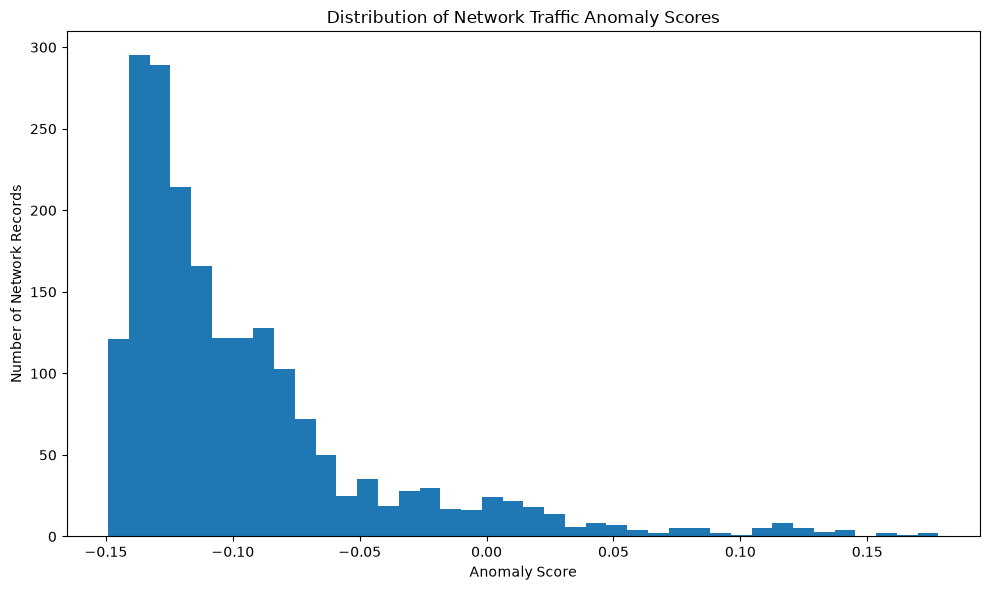

In [38]:
plt.figure(figsize=(10, 6))

plt.hist(df["AnomalyScore"], bins=40)

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Network Records")
plt.title("Distribution of Network Traffic Anomaly Scores")

plt.tight_layout()
plt.show()

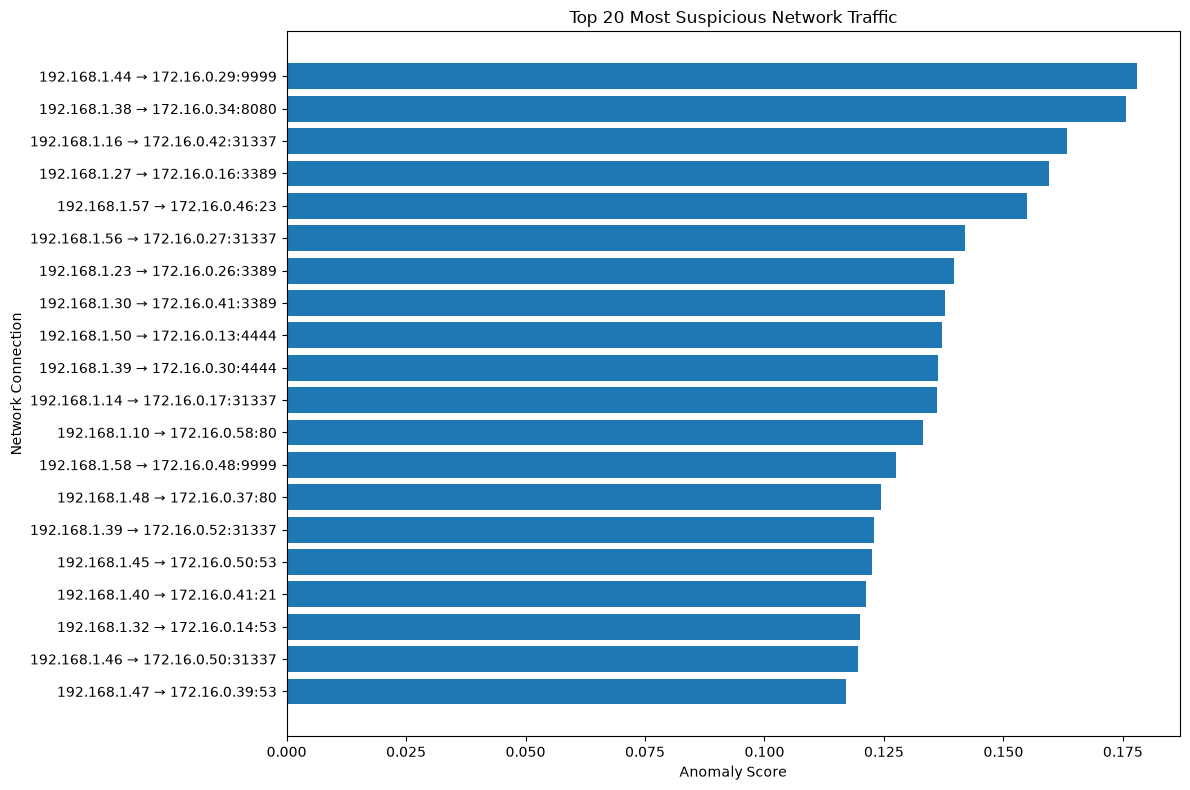

In [39]:
plt.figure(figsize=(12, 8))

plot_data = top_suspicious.copy()

plot_data["Connection"] = (
    plot_data["SourceIp"]
    + " → "
    + plot_data["DestinationIp"]
    + ":"
    + plot_data["DestinationPort"].astype(str)
)

plot_data = plot_data.sort_values("AnomalyScore")

plt.barh(
    plot_data["Connection"],
    plot_data["AnomalyScore"]
)

plt.xlabel("Anomaly Score")
plt.ylabel("Network Connection")
plt.title("Top 20 Most Suspicious Network Traffic")

plt.tight_layout()
plt.show()

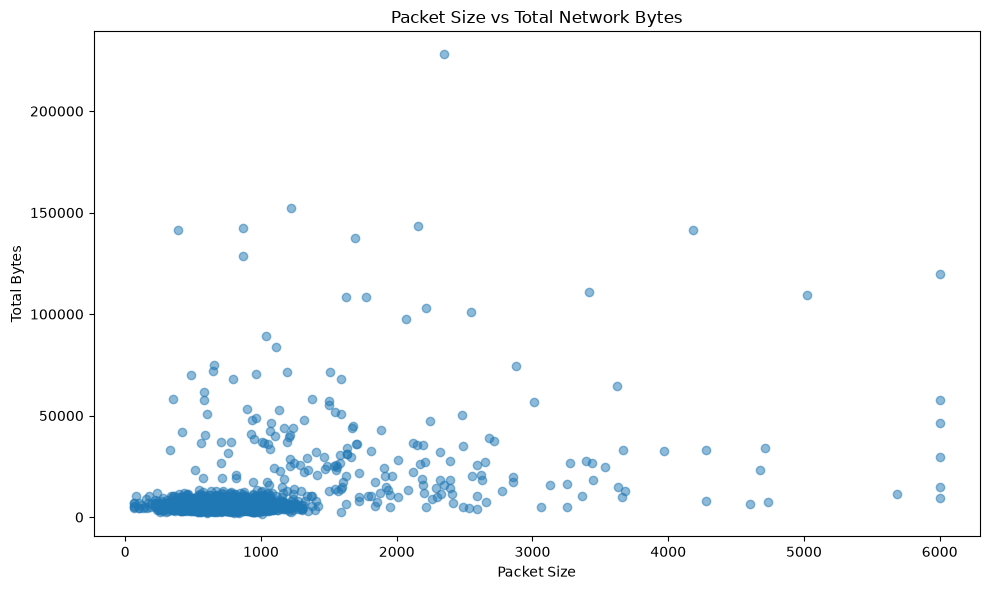

In [40]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["PacketSize"],
    df["TotalBytes"],
    alpha=0.5
)

plt.xlabel("Packet Size")
plt.ylabel("Total Bytes")
plt.title("Packet Size vs Total Network Bytes")

plt.tight_layout()
plt.show()

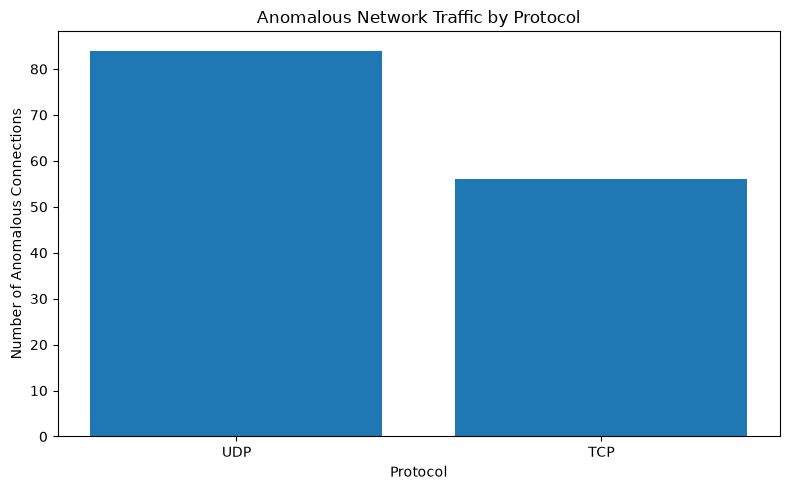

In [41]:
protocol_anomalies = (
    df[df["Prediction"] == -1]["Protocol"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

plt.bar(
    protocol_anomalies.index,
    protocol_anomalies.values
)

plt.xlabel("Protocol")
plt.ylabel("Number of Anomalous Connections")
plt.title("Anomalous Network Traffic by Protocol")

plt.tight_layout()
plt.show()

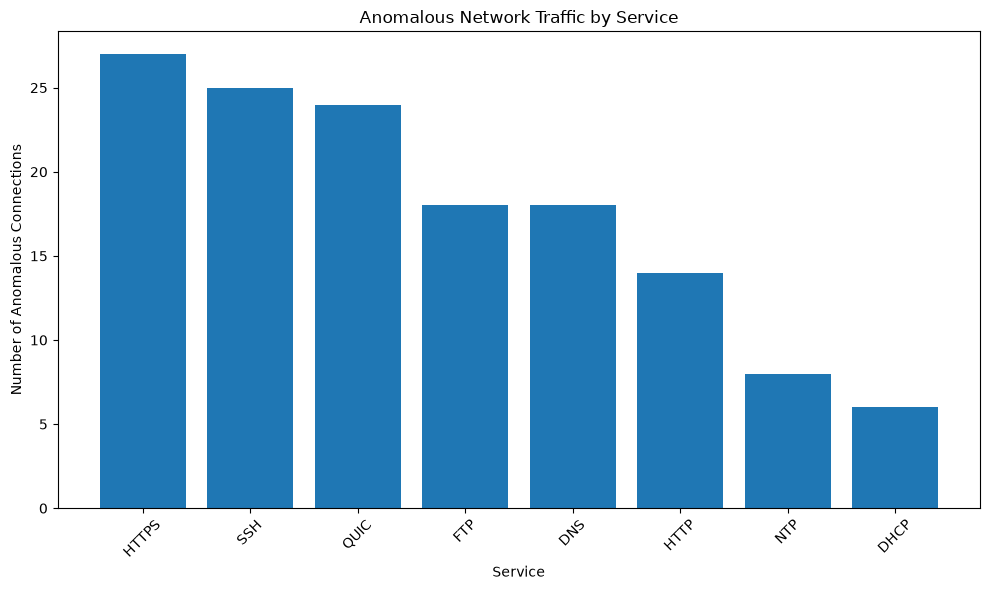

In [42]:
service_anomalies = (
    df[df["Prediction"] == -1]["Service"]
    .value_counts()
)

plt.figure(figsize=(10, 6))

plt.bar(
    service_anomalies.index,
    service_anomalies.values
)

plt.xlabel("Service")
plt.ylabel("Number of Anomalous Connections")
plt.title("Anomalous Network Traffic by Service")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

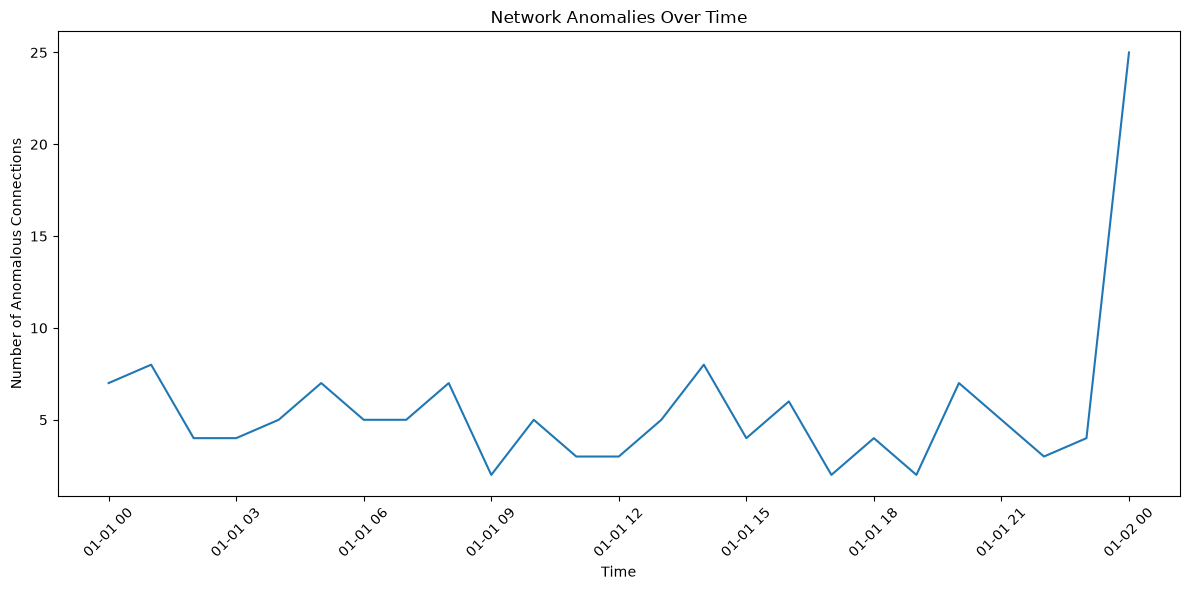

In [44]:
# Graph 6 - Anomalies Over Time

time_df = df.set_index("Timestamp")

hourly_anomalies = (
    time_df["Prediction"]
    .eq(-1)
    .resample("1h")
    .sum()
)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_anomalies.index,
    hourly_anomalies.values
)

plt.xlabel("Time")
plt.ylabel("Number of Anomalous Connections")
plt.title("Network Anomalies Over Time")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Anomaly Detection Results

In [45]:
# Overall anomaly detection summary

total_records = len(df)
anomalous_records = (df["Prediction"] == -1).sum()
normal_records = (df["Prediction"] == 1).sum()
anomaly_percentage = (anomalous_records / total_records) * 100

print("========== NETWORK TRAFFIC ANOMALY DETECTION ==========")
print(f"Total Network Records      : {total_records}")
print(f"Normal Traffic Records     : {normal_records}")
print(f"Anomalous Traffic Records  : {anomalous_records}")
print(f"Anomaly Percentage         : {anomaly_percentage:.2f}%")
print(f"Highest Anomaly Score      : {df['AnomalyScore'].max():.6f}")
print(f"Lowest Anomaly Score       : {df['AnomalyScore'].min():.6f}")

========== NETWORK TRAFFIC ANOMALY DETECTION ==========
Total Network Records      : 2000
Normal Traffic Records     : 1860
Anomalous Traffic Records  : 140
Anomaly Percentage         : 7.00%
Highest Anomaly Score      : 0.178047
Lowest Anomaly Score       : -0.149117


In [46]:
TOP_N = 20

top_suspicious = final_output.head(TOP_N).copy()

top_suspicious.insert(
    0,
    "Rank",
    range(1, len(top_suspicious) + 1)
)

top_suspicious

,Rank,SourceIp,DestinationIp,DestinationPort,PacketSize,BytesSent,BytesReceived,AnomalyScore
1985,1,192.168.1.44,172.16.0.29,9999,652,57161,17847,0.178047
44,2,192.168.1.38,172.16.0.34,8080,387,103879,37366,0.175721
137,3,192.168.1.16,172.16.0.42,31337,5021,105169,4399,0.163298
1464,4,192.168.1.27,172.16.0.16,3389,2352,200000,27989,0.159461
331,5,192.168.1.57,172.16.0.46,23,1219,2246,150000,0.154852
1977,6,192.168.1.56,172.16.0.27,31337,1169,32376,11490,0.141989
1329,7,192.168.1.23,172.16.0.26,3389,866,70255,58495,0.139638
1972,8,192.168.1.30,172.16.0.41,3389,791,63864,4022,0.137797
1180,9,192.168.1.50,172.16.0.13,4444,2876,6927,67548,0.137178
1224,10,192.168.1.39,172.16.0.30,4444,648,5782,66354,0.136218


In [47]:
# Export Top-N suspicious traffic

output_file = "top_suspicious_network_traffic.csv"

top_suspicious.to_csv(
    output_file,
    index=False
)

print(f"Report saved successfully as: {output_file}")

Report saved successfully as: top_suspicious_network_traffic.csv


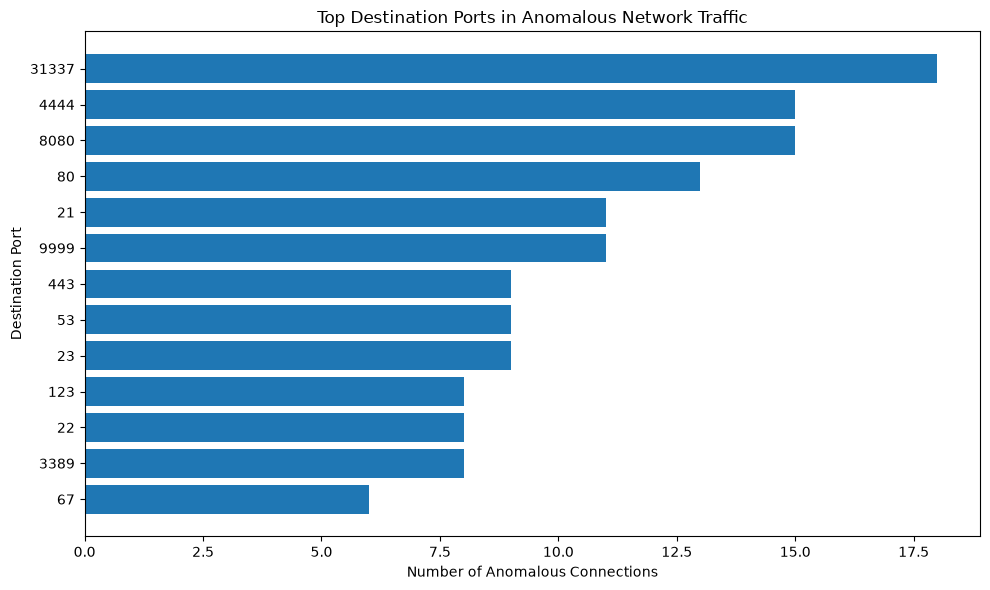

In [48]:
# Anomalous traffic by destination port

port_anomalies = (
    df[df["Prediction"] == -1]["DestinationPort"]
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    port_anomalies.index.astype(str),
    port_anomalies.values
)

plt.xlabel("Number of Anomalous Connections")
plt.ylabel("Destination Port")
plt.title("Top Destination Ports in Anomalous Network Traffic")

plt.tight_layout()
plt.show()